<a href="https://colab.research.google.com/github/b201844-source/pca-japan-prefectures/blob/main/47%E9%83%BD%E9%81%93%E5%BA%9C%E7%9C%8C%E3%81%AE%E7%94%A3%E6%A5%AD%E6%A7%8B%E9%80%A0%E3%81%A8%E4%BA%BA%E5%8F%A3%E5%8B%95%E6%85%8B%E3%81%AB%E9%96%A2%E3%81%99%E3%82%8BPCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 都道府県のクラスター分析

## 1. 目的
47都道府県を、産業構造（第1次・第2次産業就業者比率）、人口密度、人口1人あたり延べ宿泊者数の4つの数字で分類し、地域の特徴を整理する。あわせて、手法（Ward法とk-means）と前処理（対数変換）の選択が、結果にどう影響するかを確認する。


## 2. データの出どころ
| 変数 | 出典 | 年 |
|---|---|---|
| 第1次・第2次産業就業者比率 | e-Stat 国勢調査（令和7年国勢調査の参考表・不詳補完値）、表番号5-2020「産業（大分類），男女別就業者数及び人口構成比［産業別］（15歳以上就業者）－都道府県」 | 2020年 |
| 総人口・可住地面積当たり人口密度 | e-Stat「社会・人口統計体系」（都道府県・市区町村のすがた）、項目 #A011000、#A01202 | 2020年 |
| 延べ宿泊者数 | 観光庁「宿泊旅行統計調査」推移表 旧1-1（年計） | 2019年（令和元年） |

宿泊者数は2020年にコロナの影響により落ち込んでいるため、直前の2019年を用いた。
URL：【https://www.google.com/url?q=https%3A%2F%2Fwww.e-stat.go.jp%2Fstat-search%2Ffiles%3Fstat_infid%3D000040317619】　取得日：【2026年10月29日】
URL：【https://www.google.com/url?q=https%3A%2F%2Fwww.e-stat.go.jp%2Fstat-search%2Ffiles%3Fstat_infid%3D000040317619】　取得日：【2026年10月29日】
URL：【https://www.google.com/url?q=https%3A%2F%2Fwww.mlit.go.jp%2Fkankocho%2Ftokei_hakusyo%2Fshukuhakutokei.html】　取得日：【2026年10月29日】

## 3. データの加工
- 産業：数値のカンマを除去して数値化し、再掲の第1次・第2次産業就業者数を総数で割って、比率（%）を算出した。
- 人口・人口密度：同様に数値化し、「全国」の行を除いた47都道府県を使った。総人口は単位が万人で、数字の小さな県では約1%の丸め誤差がある。
- 宿泊：シート旧1-1の令和元年の列を使い、都道府県名の先頭番号を除去した。
- 人口1人あたり延べ宿泊者数 ＝ 延べ宿泊者数（2019年）÷（総人口（万人）×10000）。
- 3つの表を都道府県名で結合し、47行×6列の表を作った。欠損はなかった。


In [6]:
# ライブラリの読み込み
!pip install matplotlib-fontja -q
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_fontja
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
warnings.filterwarnings("ignore", category=UserWarning)


In [7]:
# Excel読み込み、47都道府県のdf化

# 産業：再掲の第1次、第2次を総数で割って比率（%）に変更
raw = pd.read_excel("industry_2020.xlsx", header=None, dtype=str)
h = 12                                     # 見出し行
ind = raw.iloc[h+1:].copy()
ind.columns = raw.iloc[h].tolist()
ind = ind.dropna(subset=["地域_時系列"]).set_index("地域_時系列")
total = pd.to_numeric(ind["総数"].str.replace(",", ""))
p1 = pd.to_numeric(ind["（再掲）第１次産業"].str.replace(",", ""))
p2 = pd.to_numeric(ind["（再掲）第２次産業"].str.replace(",", ""))
industry = pd.DataFrame({"primary": p1 / total * 100,
                         "secondary": p2 / total * 100})

# 人口、人口密度の全国を削除
raw2 = pd.read_excel("population_density_2020.xlsx", header=None, dtype=str)
h = 5
pop = raw2.iloc[h+1:, [1, 3, 5]].copy()
pop.columns = ["pref", "pop_man", "density"]
pop = pop.dropna(subset=["pop_man"])
pop = pop[pop["pref"] != "全国"]
pop["pop_man"] = pd.to_numeric(pop["pop_man"].str.replace(",", ""))
pop["density"] = pd.to_numeric(pop["density"].str.replace(",", ""))
pop = pop.set_index("pref")

# 宿泊列の県名先頭番号の削除
raw3 = pd.read_excel("accommodation_trend_2019.xlsx", sheet_name="旧1-1", header=None)
acc = raw3.iloc[4:, [0, 9]].copy()
acc.columns = ["pref", "acc2019"]
acc = acc[acc["pref"].astype(str).str.match(r"^\d{2}")]
acc["pref"] = acc["pref"].str[2:]
acc = acc.set_index("pref")
acc["acc2019"] = acc["acc2019"].astype(int)

# 人口1人あたりの延べ宿泊者数作成（人口単位が万人のため×10000）
df = pd.concat([industry, pop, acc], axis=1)
df["acc_per_capita"] = df["acc2019"] / (df["pop_man"] * 10000)

# 行列数と欠損値の確認
print(df.shape, df.isna().sum().sum())
df.loc[["東京都", "沖縄県"]].round(2)


(47, 6) 0


,primary,secondary,pop_man,density,acc2019,acc_per_capita
東京都,0.35,15.05,1405,9873.3,78981720,5.62
沖縄県,3.86,14.42,147,1302.6,32865670,22.36


In [19]:
#from google.colab import drive
#drive.mount('/content/drive')

## 4. 分布の確認と前処理
表2と図1は元単位の統計量と分布であり、人口密度の平均は1,351とと中央値（787）を大きく上回り、最大は9,873（東京都）だった。人口あたり宿泊者数も、平均5.23に対して最大22.36（沖縄県）で、右に長い裾をもつ。歪度は、人口密度が3.46、人口あたり宿泊者数が3.33で、第1次産業（0.24）、第2次産業（0.02）に比べて大きく偏っている。

距離をもとにするクラスタリングでは、少数の外れ値の影響を受けやすい。このため、2変数を常用対数に変換した。変換後の歪度は、人口密度が1.20、人口あたり宿泊者数が−0.22となり、偏りは小さくなった（図2は、変換後の4変数の散布図行列）。その後、4変数を平均0、標準偏差1に標準化し、単位をそろえた。

また、変換後は人口あたり宿泊者数が最も少ない埼玉県（0.74）は標準化後の値−3.51で、4変数の中で最も離れた値となった（図2、log_accのヒストグラム左端）。対数変換は、大きい外れ値を抑える一方、小さい側を引き伸ばす。


,density,primary,secondary,acc_per_capita
count,47.00,47.00,47.00,47.00
mean,1351.43,5.11,24.80,5.23
std,1791.21,2.88,5.08,3.32
min,230.20,0.35,14.42,0.74
25%,601.75,2.68,21.40,3.63
50%,786.80,4.83,23.88,4.75
75%,1260.25,7.57,28.64,5.48
max,9873.30,11.28,33.23,22.36


density           3.46
primary           0.24
secondary         0.02
acc_per_capita    3.33
dtype: float64


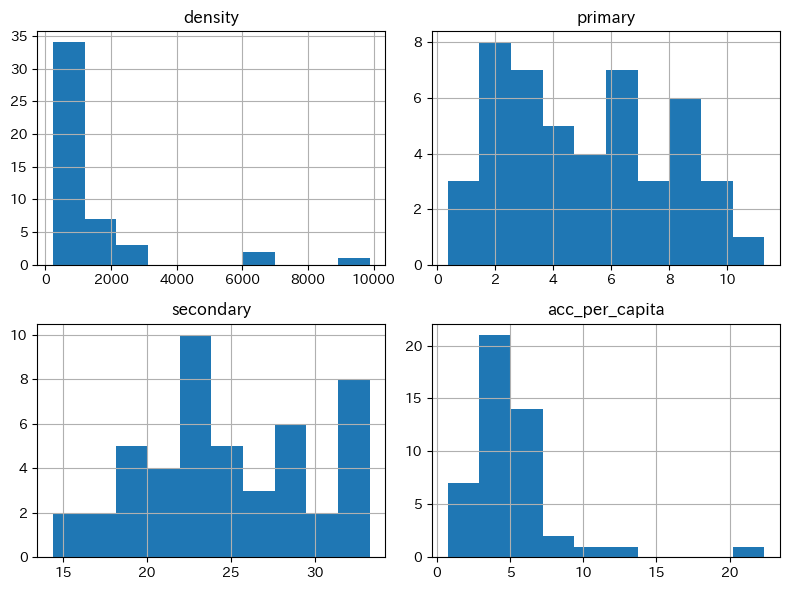

In [9]:
# 表2・図1元の単位で統計量と分布を確認
cols = ["density", "primary", "secondary", "acc_per_capita"]
display(df[cols].describe().round(2))      # 表2
print(df[cols].skew().round(2))            # 歪度（変換前）
df[cols].hist(bins=10, figsize=(8, 6))
plt.tight_layout()
plt.savefig("fig1_hist.png", dpi=150, bbox_inches="tight")
plt.show()


log_density    1.20
log_acc       -0.22
dtype: float64


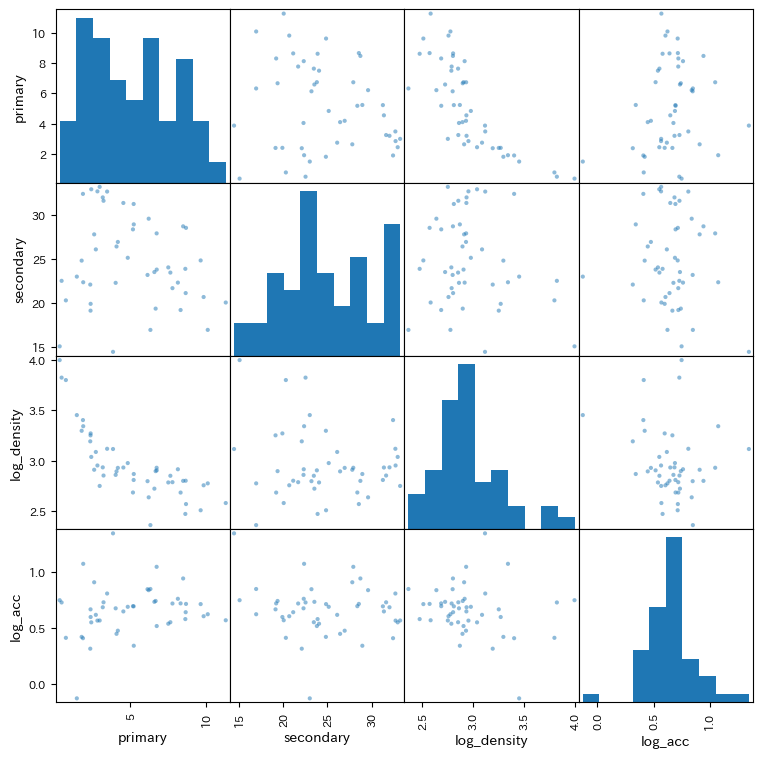

In [10]:
# 図2、2変数の対数変換と変換後の散布図行列確認
df["log_density"] = np.log10(df["density"])
df["log_acc"] = np.log10(df["acc_per_capita"])
use = ["primary", "secondary", "log_density", "log_acc"]
print(df[["log_density", "log_acc"]].skew().round(2))   # 変換後の歪度
pd.plotting.scatter_matrix(df[use], figsize=(9, 9))
plt.savefig("fig2_scatter_matrix.png", dpi=150, bbox_inches="tight")
plt.show()


In [11]:
# 4変数の単位を揃えるため平均0、標準偏差1に標準化
X = (df[use] - df[use].mean()) / df[use].std()

## 5. クラスタ数の選定
図3はWard法による樹形図で、最後4回の結合の高さは、4.37、6.20、8.99、10.43だった。2グループに分ける落差は1.44、3グループは2.79、4グループは1.83で、3グループに分ける落差が最大だった。一方、シルエット係数はk=4で最大だった。図3を距離5で切ると4グループになる。


図4はk-meansでkを2〜8に変えたときの結果で、エルボー法では、はっきりした肘は見られず、kが3〜4のあたりで減り方が緩やかになった。シルエット係数は、k=2で0.30、k=3で0.33、k=4で0.35、k=5で0.27で、k=4で最大となった。ただし、どの値も0.36未満で、グループの分離は弱かった。

あらかじめシルエット係数が最大のkを採用すると決め、k=4となった。


[ 4.37  6.2   8.99 10.43]


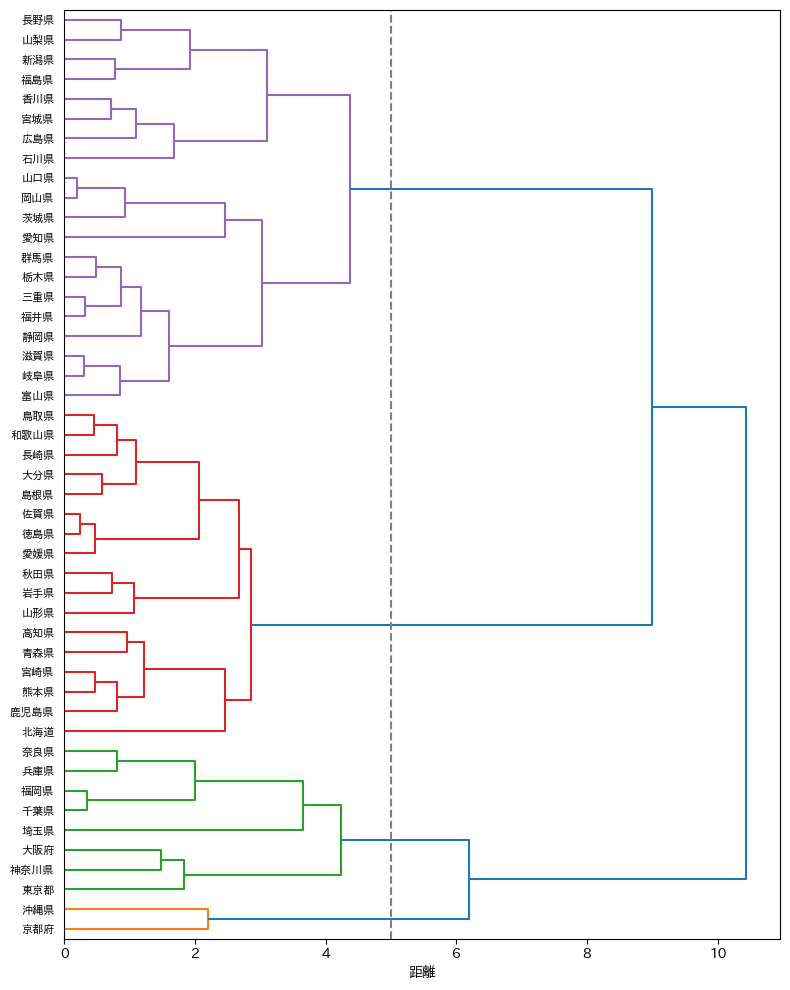

In [12]:
# 図3：Ward法でまとめて樹形図で確認
Z = linkage(X, method="ward")
print(Z[-4:, 2].round(2))                       # 4回の結合の高さ
plt.figure(figsize=(8, 10))
dendrogram(Z, labels=X.index.tolist(), orientation="right", color_threshold=5)
plt.axvline(5, linestyle="--", color="gray")    # 距離5で切ると4グループ
plt.xlabel("距離")
plt.tight_layout()
plt.savefig("fig3_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()


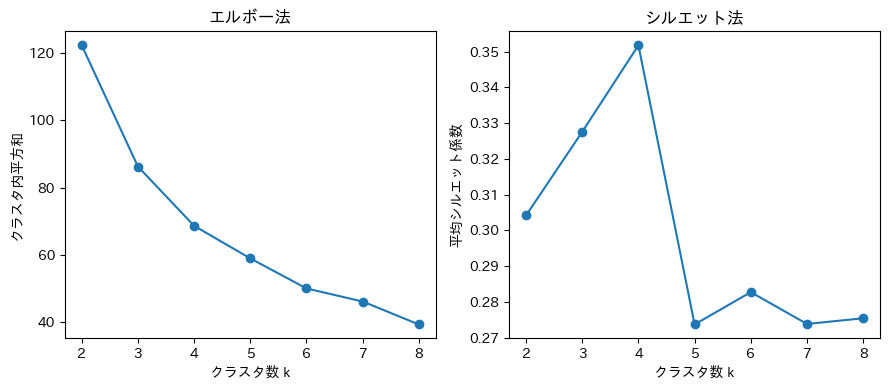

In [13]:
# 図4クラスタ数kを2〜8に変えエルボー法とシルエット係数で比較
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].plot(list(ks), inertia, marker="o")
ax[0].set_title("エルボー法")
ax[0].set_xlabel("クラスタ数 k")
ax[0].set_ylabel("クラスタ内平方和")
ax[1].plot(list(ks), sil, marker="o")
ax[1].set_title("シルエット法")
ax[1].set_xlabel("クラスタ数 k")
ax[1].set_ylabel("平均シルエット係数")
plt.tight_layout()
plt.savefig("fig4_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
# 表3、k=4のk-meansとグループ別平均の確認
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df["cluster"] = km.labels_
display(df.groupby("cluster")[cols].mean().round(1))    # 表3
for c, g in df.groupby("cluster"):
    print(c, len(g), list(g.index))

,density,primary,secondary,acc_per_capita
cluster,,,,
0,923.5,3.8,30.0,4.5
1,4093.5,1.5,20.8,3.5
2,578.9,7.9,22.6,5.4
3,1746.2,2.9,18.4,17.1


0 17 ['福島県', '茨城県', '栃木県', '群馬県', '新潟県', '富山県', '石川県', '福井県', '岐阜県', '静岡県', '愛知県', '三重県', '滋賀県', '岡山県', '広島県', '山口県', '香川県']
1 8 ['埼玉県', '千葉県', '東京都', '神奈川県', '大阪府', '兵庫県', '奈良県', '福岡県']
2 20 ['北海道', '青森県', '岩手県', '宮城県', '秋田県', '山形県', '山梨県', '長野県', '和歌山県', '鳥取県', '島根県', '徳島県', '愛媛県', '高知県', '佐賀県', '長崎県', '熊本県', '大分県', '宮崎県', '鹿児島県']
3 2 ['京都府', '沖縄県']


,primary,secondary,log_density,log_acc
PC1,0.68,-0.06,-0.67,0.29
PC2,-0.02,0.84,-0.30,-0.46


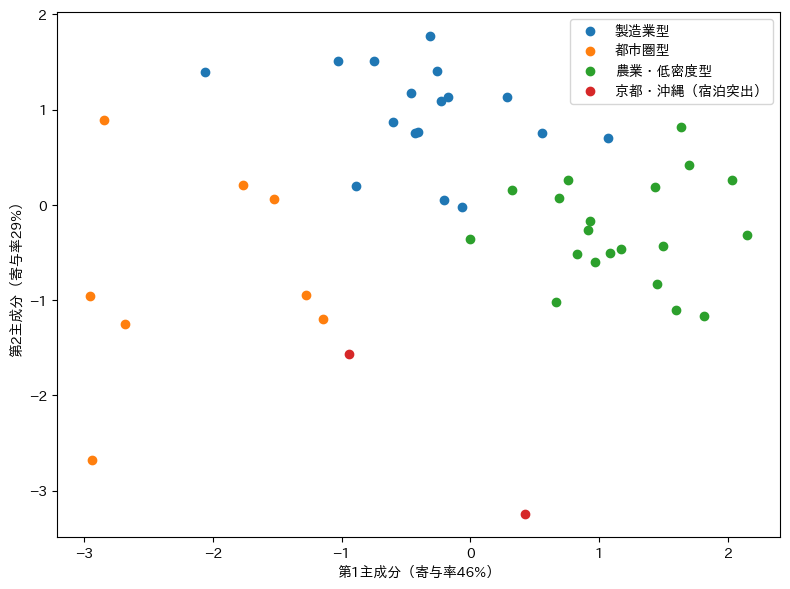

In [15]:
# 図5、4変数を主成分分析により2軸にまとめる
pca = PCA(n_components=2)
P = pca.fit_transform(X)
display(pd.DataFrame(pca.components_, columns=use, index=["PC1", "PC2"]).round(2))

# グループ名は表3から解釈
names = {0: "製造業型", 1: "都市圏型", 2: "農業・低密度型",
         3: "京都・沖縄（宿泊突出）"}
plt.figure(figsize=(8, 6))
for c in sorted(df["cluster"].unique()):
    m = (df["cluster"] == c).values
    plt.scatter(P[m, 0], P[m, 1], label=names.get(c, f"グループ{c}"))
plt.legend()
plt.xlabel(f"第1主成分（寄与率{pca.explained_variance_ratio_[0]*100:.0f}%）")
plt.ylabel(f"第2主成分（寄与率{pca.explained_variance_ratio_[1]*100:.0f}%）")
plt.tight_layout()
plt.savefig("fig5_pca.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. 結果の解釈
表3はk=4のk-meansの結果（グループ別平均）。

| グループ | 県数 | 人口密度 | 第1次産業(%) | 第2次産業(%) | 人口あたり宿泊者数 |
|---|---|---|---|---|---|
| 製造業型 | 17 | 923.5 | 3.8 | 30.0 | 4.5 |
| 都市圏型 | 8 | 4093.5 | 1.5 | 20.8 | 3.5 |
| 農業・低密度型 | 20 | 578.9 | 7.9 | 22.6 | 5.4 |
| 京都・沖縄 | 2 | 1746.2 | 2.9 | 18.4 | 17.1 |
| （全体の平均） | 47 | 1351.4 | 5.1 | 24.8 | 5.2 |

表3からの解釈によりグループ名を定めた。都市圏型は、埼玉・千葉・東京・神奈川・大阪・兵庫・奈良・福岡の8県で、人口密度が全体の約3倍、第1次産業が少ない。京都・沖縄の2県は、人口あたり宿泊者数が17.1で、全体の平均（5.2）の約3.3倍であった。

山梨県（11.2）と長野県（8.8）は、人口あたり宿泊者数が高いが、人口密度が低く、第1次産業比率が高いため、京都・沖縄ではなく、農業・低密度型に入った。

図5は4変数を主成分分析で2軸にまとめた図で、2軸で情報の約75%（46%と29%）を表す。第1主成分は、第1次産業（+0.68）と人口密度（−0.67）の対比で、地方・農業 ↔ 都市の軸にあたる。第2主成分は、第2次産業（+0.84）と人口あたり宿泊者数（−0.46）の対比で、製造業 ↔ 宿泊の軸にあたる。


## 7. 手法の比較（k-means と Ward法）
表4はk-meansとWard法（いづれもk=4）分類の対応表で、両方の一致度を表す調整ランド指数（ARI）は0.79だった。

都市圏型の8県と、京都・沖縄の2県は、両方で一致した。一致しなかったのは、宮城・山梨・長野の3県で、k-meansでは農業・低密度型、Ward法では製造業型に入った。この3県から、標準化後の空間での、2つのグループの中心までの距離を調べると、宮城県は製造業型1.55・農業・低密度型1.39、山梨県は2.16・1.97、長野県は2.19・1.63だった。

山梨県（11.2）と長野県（8.8）は、人口あたり宿泊者数が高いが、人口密度が低く、第1次産業比率が高いため、京都・沖縄ではなく、農業・低密度型の側に入った。ただし、第2次産業比率も高め（27.9%、28.7%）で、製造業型にも近い。

図5では、京都府は都市圏型の点の近くに、沖縄県は下端に離れて位置し、2府県は近くない。2府県の共通点は、人口あたり宿泊者数が高いことで、この変数は第2主成分に強く反映される。また、製造業型と農業・低密度型の点は、境界付近で重なっている。主成分の2軸は、情報の約75%しか表さないので、図における都道府県間の距離は、4次元の距離と一致しない。




In [16]:
# 表4、k-meansとWard法で一致しなかった県
df["ward"] = fcluster(Z, 4, criterion="maxclust")
print(pd.crosstab(df["cluster"], df["ward"]))
print("ARI:", round(adjusted_rand_score(df["cluster"], df["ward"]), 2))

# 各k-meansグループで最多のWard法の番号と異なる都道府県
main = pd.crosstab(df["cluster"], df["ward"]).idxmax(axis=1)
df["ward_main"] = df["cluster"].map(main)
diff = df.index[df["ward"] != df["ward_main"]].tolist()
print(diff)

# 4つのグループ中心までの距離
for p in diff:
    d = np.linalg.norm(km.cluster_centers_ - X.loc[p].values, axis=1)
    print(p, d.round(2))


ward     1  2   3   4
cluster              
0        0  0   0  17
1        0  8   0   0
2        0  0  17   3
3        2  0   0   0
ARI: 0.79
['宮城県', '山梨県', '長野県']
宮城県 [1.55 2.32 1.39 2.76]
山梨県 [2.16 3.85 1.97 2.57]
長野県 [2.19 4.14 1.63 3.31]


## 8. 前処理の影響（対数変換の有無）
対数変換をせず、標準化だけでk=4のk-meansを行うと、グループの大きさは2・3・19・23県となった。小さい2つのグループは、東京・神奈川・大阪の3県と、京都・沖縄の2県である。対数変換ありの結果（17・8・20・2県）との一致度（ARI）は0.72だった。

シルエット係数は、変換あり0.35、変換なし0.39で、変換なしのほうが高い。ただし、外れ値を別のグループにしたことで上がった可能性があり、数字だけでは決められなかった。対数変換の有無で分類が変わることが確認できた。


In [17]:
# 対数変換の有無による影響の確認
use_raw = ["primary", "secondary", "density", "acc_per_capita"]
X_raw = (df[use_raw] - df[use_raw].mean()) / df[use_raw].std()
km_raw = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_raw)
print(sorted(pd.Series(km_raw.labels_).value_counts().tolist()))
print("ARI:", round(adjusted_rand_score(df["cluster"], km_raw.labels_), 2))
print("シルエット:", round(silhouette_score(X_raw, km_raw.labels_), 2))
s = pd.Series(km_raw.labels_, index=df.index)
for c, g in s.groupby(s):
    if len(g) <= 4:
        print(list(g.index))


[2, 3, 19, 23]
ARI: 0.72
シルエット: 0.39
['東京都', '神奈川県', '大阪府']
['京都府', '沖縄県']


In [18]:
# 分析に使った値とグループ番号のCSV保存
out = df[["pop_man", "density", "primary", "secondary",
          "acc2019", "acc_per_capita", "cluster"]]
out.to_csv("prefecture_cluster_data.csv", encoding="utf-8-sig")
# files.download("prefecture_cluster_data.csv")


## 9. 考察と限界
- 都市圏型、製造業型、農業・低密度型、京都・沖縄の4つに分け、47都道府県の特徴を整理した。ただし、シルエット係数は0.35と低く、グループの分離は弱かった。
- 2つの手法の一致度は0.79で、境界上の3県を除くと、分類は一致した。
- 対数変換の有無で分類が変わった。今回は外れ値の影響を抑えるために対数変換を採用した。

限界：
- 47都道府県・4変数で結果は変数の選び方に依存する。
- 京都・沖縄の2県のグループは一般化できない。
- 延べ宿泊者数は観光と出張を区別できないため、人口あたりの値は目安となる。
- 年次は産業・人口が2020年、宿泊が2019年で1年ずれている。
- 総人口は単位が万人であり、数値の小さい県では約1%の丸め誤差がある。
- 主成分分析の2次元図は、4次元の情報の約75%にとどまった。
- 図5の2次元の位置は、4次元の距離を正確に表していない（京都・沖縄の2県は、図では離れている）。グループ名は、表3からの解釈となっている。
